In [1]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import random
import numpy as np
from PIL import Image

# Cấu hình hiển thị
plt.rcParams['figure.figsize'] = (12, 8)
pd.set_option('display.max_colwidth', None)

# 1. Tự động tìm đường dẫn gốc của dataset
# Trên Kaggle, dataset thường nằm trong /kaggle/input/
root_dir = '/kaggle/input/face-detection-dataset'

print(f"Checking directory: {root_dir}")
for dirpath, dirnames, filenames in os.walk(root_dir):
    if len(filenames) > 0:
        print(f"Found {len(filenames)} files in {dirpath}")
        # In thử 3 file đầu tiên để xem định dạng
        print(f"Sample files: {filenames[:3]}")
        break # Chỉ in folder đầu tiên chứa file để tránh spam log

Checking directory: /kaggle/input/face-detection-dataset
Found 16733 files in /kaggle/input/face-detection-dataset/labels2
Sample files: ['90cc772eb8d72107.txt', 'e1a2c8159797b77b.txt', 'c171fa4ac2a6280d.txt']


Tổng số lượng ảnh tìm thấy: 16733
BẢNG THỐNG KÊ DATASET
Tổng số ảnh: 16733
Số ảnh có file nhãn đi kèm: 16733
Tổng số khuôn mặt (bounding boxes): 51846
Trung bình số mặt trên một ảnh: 3.10
Số ảnh không có khuôn mặt (Background): 0
------------------------------


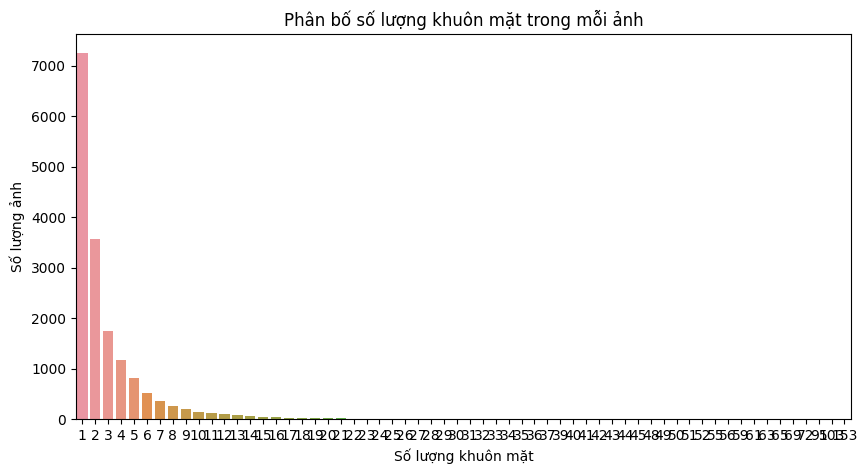

In [2]:
# Giả định cấu trúc dataset này để file ảnh và label chung hoặc tách folder
# Ta sẽ dùng glob để lấy toàn bộ đường dẫn
image_extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
image_paths = []

for ext in image_extensions:
    # Tìm kiếm đệ quy trong thư mục gốc
    image_paths.extend(glob.glob(os.path.join(root_dir, '**', ext), recursive=True))

print(f"Tổng số lượng ảnh tìm thấy: {len(image_paths)}")

# Tạo DataFrame để lưu thông tin
data = []

for img_path in image_paths:
    # Giả định file label cùng tên với ảnh nhưng đuôi .txt (YOLO format)
    # Nếu dataset này để label ở folder khác, ta cần thay thế đường dẫn (thường là thay 'images' thành 'labels')
    
    # Thử tìm file label ở cùng thư mục trước (cấu trúc thường thấy)
    label_path = os.path.splitext(img_path)[0] + '.txt'
    
    # Nếu không thấy, thử thay thế path (nếu cấu trúc là /images và /labels riêng biệt)
    if not os.path.exists(label_path):
        label_path = label_path.replace('images', 'labels')
        
    num_faces = 0
    box_data = [] # Lưu width, height của box để phân tích kích thước
    
    if os.path.exists(label_path):
        try:
            with open(label_path, 'r') as f:
                lines = f.readlines()
                num_faces = len(lines)
                for line in lines:
                    # YOLO format: class x_center y_center width height
                    parts = list(map(float, line.strip().split()))
                    if len(parts) >= 5:
                        box_data.append(parts[3:]) # Lấy width, height
        except Exception as e:
            print(f"Lỗi đọc file {label_path}: {e}")
            
    data.append({
        'image_path': img_path,
        'label_path': label_path if os.path.exists(label_path) else None,
        'has_label': os.path.exists(label_path),
        'num_faces': num_faces,
        'box_sizes': box_data
    })

df = pd.DataFrame(data)

# --- HIỂN THỊ THỐNG KÊ ---
print("="*30)
print("BẢNG THỐNG KÊ DATASET")
print("="*30)
print(f"Tổng số ảnh: {len(df)}")
print(f"Số ảnh có file nhãn đi kèm: {df['has_label'].sum()}")
print(f"Tổng số khuôn mặt (bounding boxes): {df['num_faces'].sum()}")
print(f"Trung bình số mặt trên một ảnh: {df['num_faces'].mean():.2f}")
print(f"Số ảnh không có khuôn mặt (Background): {len(df[df['num_faces'] == 0])}")
print("-" * 30)

# Vẽ biểu đồ phân bố số lượng mặt
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='num_faces')
plt.title('Phân bố số lượng khuôn mặt trong mỗi ảnh')
plt.xlabel('Số lượng khuôn mặt')
plt.ylabel('Số lượng ảnh')
plt.show()

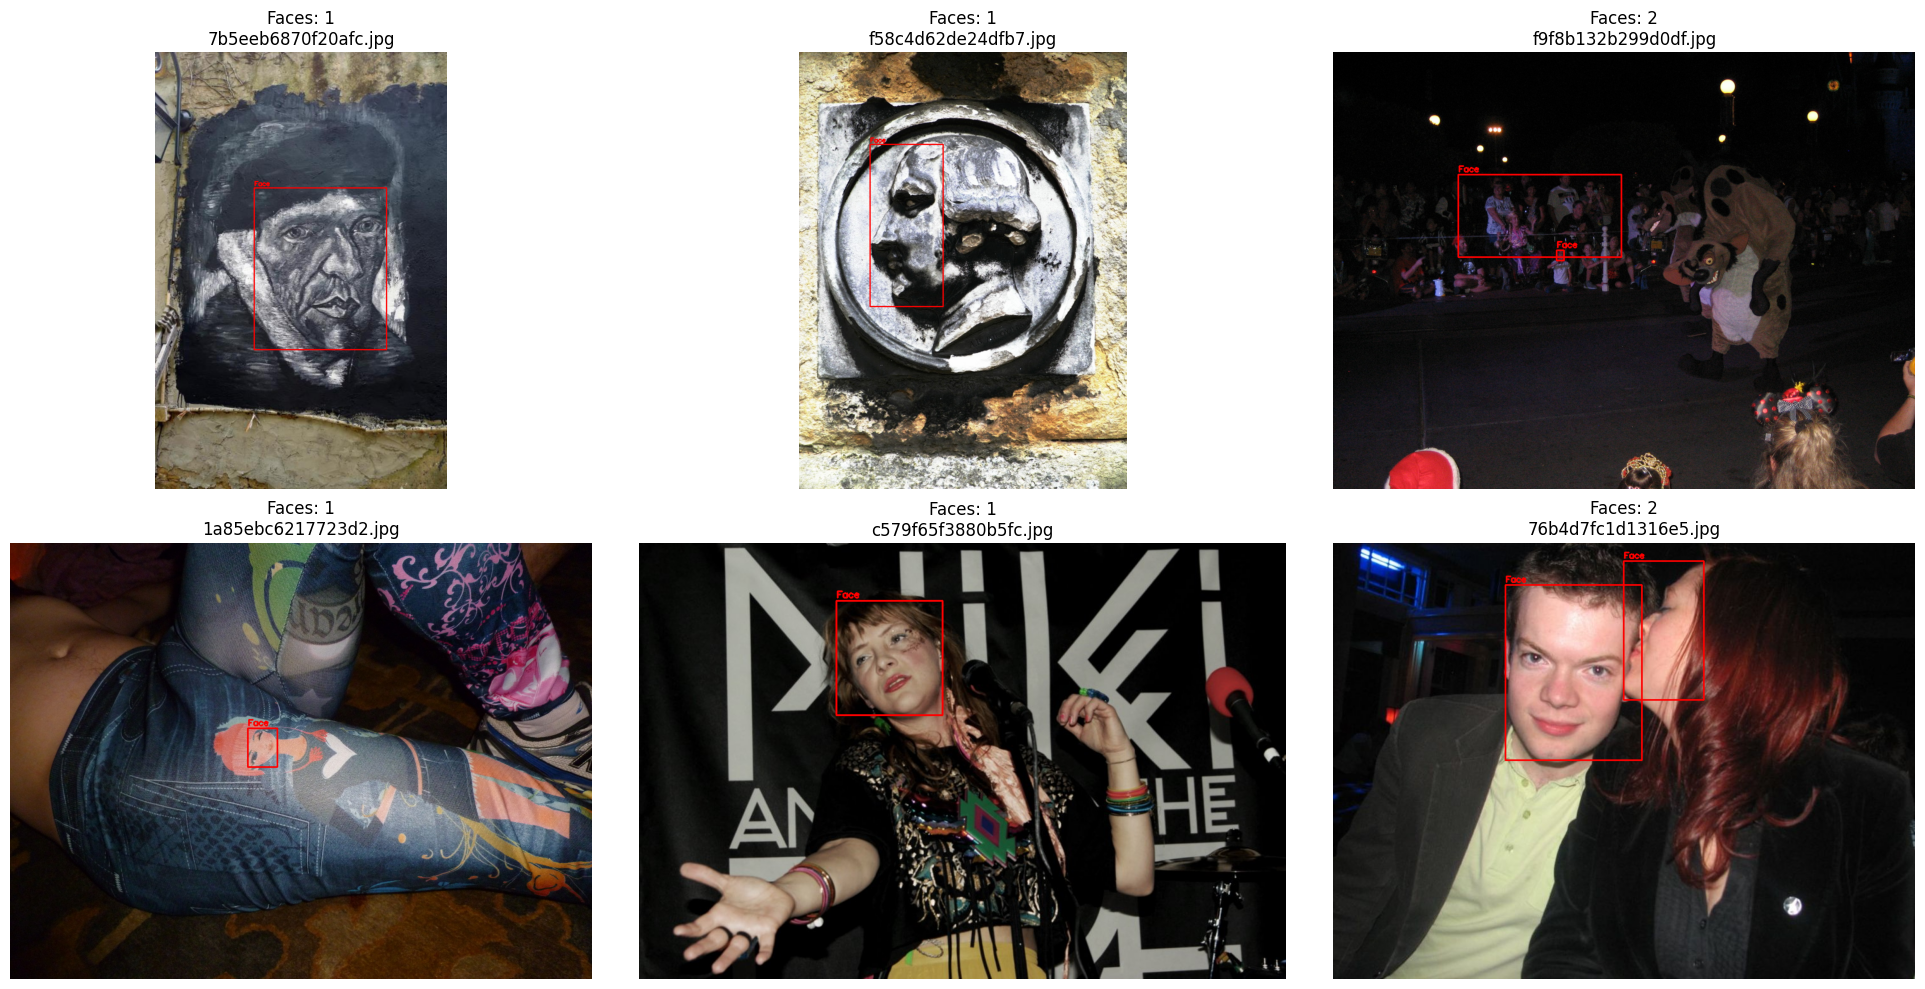

In [3]:
def plot_samples(df, num_samples=6):
    # Lấy ngẫu nhiên các ảnh có label
    sample_df = df[df['num_faces'] > 0].sample(n=num_samples, random_state=42)
    
    plt.figure(figsize=(20, 10))
    
    for idx, (_, row) in enumerate(sample_df.iterrows()):
        img_path = row['image_path']
        label_path = row['label_path']
        
        # Đọc ảnh bằng OpenCV
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape
        
        # Đọc label và vẽ box
        with open(label_path, 'r') as f:
            lines = f.readlines()
            for line in lines:
                parts = list(map(float, line.strip().split()))
                # format: class x_center y_center width height
                # Tọa độ chuẩn hóa (0-1)
                cls, x_c, y_c, w_box, h_box = parts[0], parts[1], parts[2], parts[3], parts[4]
                
                # Chuyển sang pixel
                x_min = int((x_c - w_box/2) * w)
                y_min = int((y_c - h_box/2) * h)
                x_max = int((x_c + w_box/2) * w)
                y_max = int((y_c + h_box/2) * h)
                
                # Vẽ hình chữ nhật (Màu đỏ, độ dày 2)
                cv2.rectangle(img, (x_min, y_min), (x_max, y_max), (255, 0, 0), 2)
                
                # Ghi tên class (thường là 0: Face)
                cv2.putText(img, f"Face", (x_min, y_min - 5), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

        plt.subplot(2, 3, idx+1)
        plt.imshow(img)
        plt.title(f"Faces: {row['num_faces']}\n{os.path.basename(img_path)}")
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# Gọi hàm vẽ
plot_samples(df)